# 📘 Notebook 12: Tuning Without Searching, Zero-Shot AutoML and Pretrained Models

### Course: *From Defaults to Decisions: Hyperparameters, Explained by Experiment*
**Instructor:** Ioannis Tsioulis

---

> 💡 **This notebook is already run.** Every number and chart below was produced by the code above it, and each result is followed by a comment that explains what it shows. You can read it without running anything, or choose **Runtime → Run all** in Colab (the first cell installs the two libraries).
>
> ⏱️ **Training time and limitations.** About **twenty minutes** on an ordinary processor, almost all of it spent by TabPFN, which is designed for a **GPU**: on a Colab GPU (**Runtime → Change runtime type**) the same cells take a few minutes. We use **3,000** training rows of one tabular dataset; TabPFN version 2 is designed for up to about 10,000 rows and 500 columns. Results on other datasets will differ, and with one dataset the ranking of the methods is an example, not a law.

## 🎯 Learning objectives

By the end of this notebook you will be able to:

- Explain **meta-learning** for hyperparameters: learning good settings from many **earlier** datasets
- Use **FLAML zero-shot** to get hyperparameters for LightGBM **without any search**
- Use **TabPFN**, a pretrained model that makes predictions on a new table **without training or tuning**
- Compare defaults, an Optuna search, zero-shot settings and TabPFN fairly: **accuracy and time**
- Say where these methods work (small and medium tables) and where they do not yet (images, text, large neural networks)

> **Prerequisites:** [Notebook 11: Automatic Hyperparameter Search with Optuna](https://colab.research.google.com/github/giannis00/giannis00.github.io/blob/main/assets/jupyter/from-defaults-to-decisions/11_optuna.ipynb). The dataset is the one explored in [From Questions to Answers, Notebook 04](https://giannis00.github.io/teaching/#classic-datasets).
>
> 🔭 **Why this notebook matters:** Notebook 11 found good settings by trying many of them. A natural question follows: if thousands of people have already tuned models on thousands of datasets, why does every new project start the search from zero? Two families of tools answer it: **zero-shot AutoML**, which predicts good hyperparameters for your data from what worked on similar data, and **tabular foundation models**, which skip training altogether.

## 1. The papers

> 📄 Meta-learning for AutoML: M. Feurer, A. Klein, K. Eggensperger, J. Springenberg, M. Blum and F. Hutter, [*Efficient and Robust Automated Machine Learning*](https://papers.nips.cc/paper/2015/hash/11d0e6287202fced83f79975ec59a3a6-Abstract.html), NeurIPS 2015 (auto-sklearn).
>
> 📄 FLAML zero-shot: M. Kayali and C. Wang, [*Mining Robust Default Configurations for Resource-constrained AutoML*](https://arxiv.org/abs/2202.09927), 2022.
>
> 📄 TabPFN: N. Hollmann, S. Müller, K. Eggensperger and F. Hutter, [*TabPFN: A Transformer That Solves Small Tabular Classification Problems in a Second*](https://arxiv.org/abs/2207.01848), ICLR 2023; and N. Hollmann et al., [*Accurate predictions on small data with a tabular foundation model*](https://www.nature.com/articles/s41586-024-08328-6), Nature 637, 2025 (TabPFN version 2).

### Intuition first
- **Search** (Notebook 11): try settings on **your** data, keep the best. Reliable, but every trial is a full training.
- **Zero-shot AutoML**: the library's authors have already searched on **hundreds of datasets** and stored a small set of settings that work well, together with a rule for choosing among them from simple facts about the data (number of rows, columns, classes, share of numeric columns). On your data it **looks up** a setting: one training, no search.
- **TabPFN**: a Transformer trained once, on millions of **synthetic** tables, to predict the labels of new rows given labelled example rows. On your data it does not train at all: the training rows are its **input**, read in one pass, like the examples in a prompt to a language model.

In [ ]:
%pip install -q "flaml[autozero]" "tabpfn==2.0.9"

In [1]:
import os, time, warnings
os.environ["TABPFN_ALLOW_CPU_LARGE_DATASET"] = "1"   # TabPFN refuses more than 1,000 rows on a CPU unless asked
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
import lightgbm as lgb
from sklearn.metrics import accuracy_score, roc_auc_score
from flaml.default import preprocess_and_suggest_hyperparams, LGBMClassifier as ZeroShotLGBM
from tabpfn import TabPFNClassifier
optuna.logging.set_verbosity(optuna.logging.WARNING)

URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
columns = ["age", "workclass", "fnlwgt", "education", "education_num", "marital_status", "occupation", "relationship",
           "race", "sex", "capital_gain", "capital_loss", "hours_per_week", "native_country", "income"]
df = pd.read_csv(URL, names=columns, skipinitialspace=True, na_values="?")
y_all = (df.pop("income") == ">50K").astype(int)
X_all = df.drop(columns=["education"])            # education_num carries the same information as a number
CATEGORICAL = ["workclass", "marital_status", "occupation", "relationship", "race", "sex", "native_country"]
for c in CATEGORICAL:
    X_all[c] = X_all[c].astype("category").cat.codes   # categories as integer codes (-1 = missing)
CAT_IDX = [list(X_all.columns).index(c) for c in CATEGORICAL]

order = np.random.default_rng(0).permutation(len(X_all))
test_idx, val_idx, pool_idx = order[:2000], order[2000:3000], order[3000:]
X_test, y_test = X_all.iloc[test_idx], y_all.iloc[test_idx]
X_val, y_val = X_all.iloc[val_idx], y_all.iloc[val_idx]
X_train, y_train = X_all.iloc[pool_idx[:3000]], y_all.iloc[pool_idx[:3000]]
print(f"{len(X_all):,} rows, {X_all.shape[1]} columns; train {len(X_train):,}, validation {len(X_val):,}, test {len(X_test):,}")
print(f"share earning more than 50K: {y_train.mean():.3f}")

def score(proba):
    return {"accuracy": accuracy_score(y_test, proba > 0.5), "ROC AUC": roc_auc_score(y_test, proba)}

32,561 rows, 13 columns; train 3,000, validation 1,000, test 2,000
share earning more than 50K: 0.231


## 2. Four ways to set up a model

All four use the same 3,000 training rows and are scored once on the same 2,000 test rows. Optuna also uses the 1,000 validation rows to choose; the others never see them.

### 2a. LightGBM with its defaults

In [2]:
results = {}
start = time.time()
default = lgb.LGBMClassifier(verbose=-1, random_state=0).fit(X_train, y_train)
results["LightGBM defaults"] = {**score(default.predict_proba(X_test)[:, 1]), "seconds": time.time() - start, "trainings": 1}
results["LightGBM defaults"]

{'accuracy': 0.8525,
 'ROC AUC': 0.9169990241848299,
 'seconds': 1.8298437595367432,
 'trainings': 1}

### 2b. LightGBM tuned by Optuna (40 trials)

In [3]:
def objective(trial):
    params = {"n_estimators": trial.suggest_int("n_estimators", 50, 1000, log=True),
              "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.3, log=True),
              "num_leaves": trial.suggest_int("num_leaves", 4, 256, log=True),
              "min_child_samples": trial.suggest_int("min_child_samples", 2, 100, log=True),
              "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
              "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True)}
    m = lgb.LGBMClassifier(**params, verbose=-1, random_state=0).fit(X_train, y_train)
    return roc_auc_score(y_val, m.predict_proba(X_val)[:, 1])

start = time.time()
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=0))
study.optimize(objective, n_trials=40)
tuned = lgb.LGBMClassifier(**study.best_params, verbose=-1, random_state=0).fit(X_train, y_train)
results["LightGBM + Optuna (40 trials)"] = {**score(tuned.predict_proba(X_test)[:, 1]), "seconds": time.time() - start, "trainings": 41}
print("best setting found:", {k: round(v, 4) if isinstance(v, float) else v for k, v in study.best_params.items()})
results["LightGBM + Optuna (40 trials)"]

best setting found: {'n_estimators': 218, 'learning_rate': 0.0701, 'num_leaves': 5, 'min_child_samples': 2, 'colsample_bytree': 0.3301, 'reg_lambda': 5.1845}


{'accuracy': 0.8605,
 'ROC AUC': 0.9232520693895014,
 'seconds': 5.1011738777160645,
 'trainings': 41}

### 2c. LightGBM with FLAML zero-shot settings

`preprocess_and_suggest_hyperparams` looks at the training data and returns the settings it recommends, without training anything. `flaml.default.LGBMClassifier` does the same inside `fit`, so it can be used exactly like an ordinary LightGBM model.

In [4]:
suggested, *_ = preprocess_and_suggest_hyperparams("classification", X_train, y_train, "lgbm")
print("settings chosen for this dataset, without any trial:")
for k, v in suggested.items():
    print(f"  {k:18s} {round(v, 4) if isinstance(v, float) else v}")
print("LightGBM defaults for comparison: n_estimators 100, num_leaves 31, learning_rate 0.1, min_child_samples 20")

start = time.time()
zero_shot = ZeroShotLGBM().fit(X_train, y_train)
results["LightGBM + FLAML zero-shot"] = {**score(zero_shot.predict_proba(X_test)[:, 1]), "seconds": time.time() - start, "trainings": 1}
results["LightGBM + FLAML zero-shot"]

settings chosen for this dataset, without any trial:
  n_estimators       141
  num_leaves         139
  min_child_samples  8
  learning_rate      0.0482
  colsample_bytree   0.5261
  reg_alpha          0.0029
  reg_lambda         0.0245
  max_bin            511
  verbose            -1
LightGBM defaults for comparison: n_estimators 100, num_leaves 31, learning_rate 0.1, min_child_samples 20


{'accuracy': 0.846,
 'ROC AUC': 0.9110483062251069,
 'seconds': 0.4349052906036377,
 'trainings': 1}

**What we see.** FLAML looked at the training data (3,000 rows, 12 columns, two classes) and, without a single trial, chose settings quite different from LightGBM's defaults: **139 leaves** per tree instead of 31, a smaller learning rate (0.048 instead of 0.1), **141** trees, only half of the columns for each tree (`colsample_bytree` 0.53) and fine-grained bins (`max_bin` 511). These are not arbitrary: they are the configuration that performed most robustly on the datasets most similar to ours in the collection FLAML was mined on.

Training with them took **0.4 seconds**, but the test ROC AUC, **0.911**, is slightly **below** the plain defaults (0.917). On this dataset, at this size, the suggestion is not better than the defaults; Sections 3 and 4 show when it is.

### 2d. TabPFN: no training, no hyperparameters

`fit` only stores the 3,000 training rows and prepares them; the work happens in `predict_proba`, where the Transformer reads the training rows and the test rows together. We tell it which columns are categories.

In [5]:
start = time.time()
tabpfn = TabPFNClassifier(device="cpu", categorical_features_indices=CAT_IDX, random_state=0).fit(X_train, y_train)
results["TabPFN (pretrained)"] = {**score(tabpfn.predict_proba(X_test)[:, 1]), "seconds": time.time() - start, "trainings": 0}
results["TabPFN (pretrained)"]

{'accuracy': 0.861,
 'ROC AUC': 0.9207389741658669,
 'seconds': 619.6476421356201,
 'trainings': 0}

## 3. The comparison

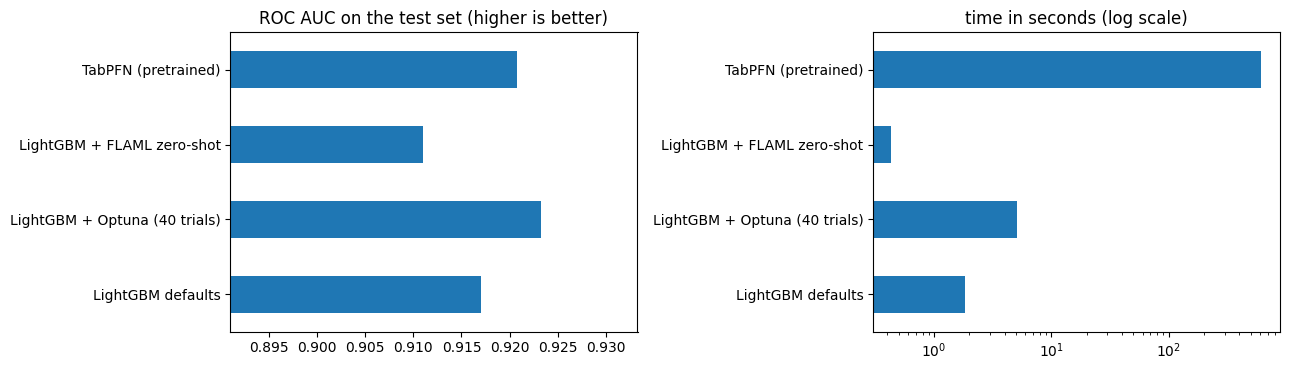

,accuracy,ROC AUC,seconds,trainings
LightGBM defaults,0.8525,0.9170,1.8298,1.0
LightGBM + Optuna (40 trials),0.8605,0.9233,5.1012,41.0
LightGBM + FLAML zero-shot,0.8460,0.9110,0.4349,1.0
TabPFN (pretrained),0.8610,0.9207,619.6476,0.0


In [6]:
table = pd.DataFrame(results).T
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
table["ROC AUC"].plot.barh(ax=axes[0], xlim=(table["ROC AUC"].min() - 0.02, table["ROC AUC"].max() + 0.01), title="ROC AUC on the test set (higher is better)")
table["seconds"].plot.barh(ax=axes[1], logx=True, title="time in seconds (log scale)")
plt.tight_layout()
plt.show()
table.round(4)

**What we see.** The four results, on the same 2,000 test rows:
- **Optuna** gives the best ROC AUC (**0.923**) and accuracy (86.1%), after 41 trainings in **5 seconds**: LightGBM on 3,000 rows trains so fast that a search is cheap. Its best setting is the opposite of FLAML's: very small trees (**5 leaves**), many columns left out and strong regularisation (`reg_lambda` 5.2).
- **TabPFN**, with no training and no tuning, comes close (**0.921**, 86.1% accuracy), but needed **620 seconds** on a processor: about a hundred times longer than the whole Optuna search.
- **LightGBM defaults** are a solid baseline (0.917), and **FLAML zero-shot** is slightly below them (0.911).

The differences are small: 0.012 in ROC AUC between best and worst, about one point of accuracy. The honest conclusion for this dataset: when the model trains in a fraction of a second, a short search is cheap and worth it; a suggestion made without looking at the data can miss what this dataset prefers (here, simple, heavily regularised trees).

## 4. Does the amount of data change the picture?

TabPFN was trained on small synthetic tables, and zero-shot settings were mined from many datasets of different sizes. We repeat the comparison with **250**, **1,000** and **3,000** training rows, three random samples each. To keep the time reasonable on a processor, TabPFN uses one ensemble member (`n_estimators=1`) instead of its default four, which costs it a little accuracy.

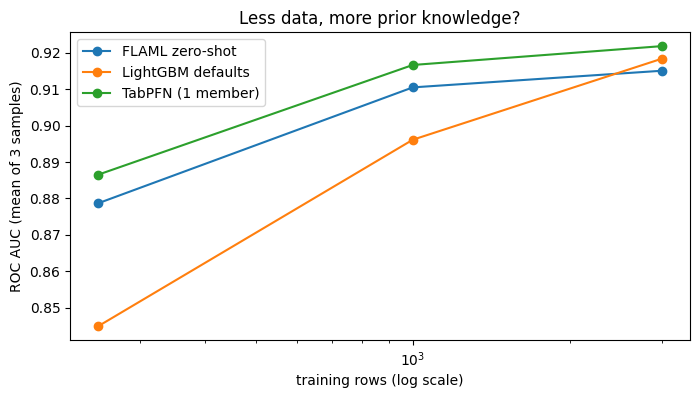

ROC AUC                                      \
method        FLAML zero-shot LightGBM defaults TabPFN (1 member)   
training rows                                                       
250                    0.8787            0.8449            0.8865   
1000                   0.9105            0.8961            0.9166   
3000                   0.9150            0.9184            0.9218   

                      seconds                                      
method        FLAML zero-shot LightGBM defaults TabPFN (1 member)  
training rows                                                      
250                    0.2520            0.0664            5.7849  
1000                   0.6139            0.1324           19.1753  
3000                   0.7240            0.1873           93.0787

In [7]:
rows = []
for n in [250, 1000, 3000]:
    for seed in range(3):
        pick = np.random.default_rng(seed).choice(pool_idx, size=n, replace=False)
        Xs, ys = X_all.iloc[pick], y_all.iloc[pick]
        models = {"LightGBM defaults": lambda: lgb.LGBMClassifier(verbose=-1, random_state=0),
                  "FLAML zero-shot": lambda: ZeroShotLGBM(),
                  "TabPFN (1 member)": lambda: TabPFNClassifier(device="cpu", n_estimators=1, categorical_features_indices=CAT_IDX, random_state=0)}
        for name, make in models.items():
            start = time.time()
            proba = make().fit(Xs, ys).predict_proba(X_test)[:, 1]
            rows.append({"training rows": n, "method": name, "seed": seed, "ROC AUC": roc_auc_score(y_test, proba), "seconds": time.time() - start})
sizes = pd.DataFrame(rows)
summary = sizes.groupby(["training rows", "method"])[["ROC AUC", "seconds"]].mean().unstack("method")
fig, ax = plt.subplots(figsize=(8, 4))
for name in summary["ROC AUC"].columns:
    ax.semilogx(summary.index, summary["ROC AUC"][name], marker="o", label=name)
ax.set_xlabel("training rows (log scale)"); ax.set_ylabel("ROC AUC (mean of 3 samples)"); ax.legend(); ax.set_title("Less data, more prior knowledge?")
plt.show()
summary.round(4)

**What we see.** The amount of data changes the picture, and this is where prior knowledge earns its keep:
- With **250** rows, plain defaults are clearly weakest (**0.845**). FLAML's zero-shot settings, chosen for a dataset of that size, gain **3.4** points of AUC (0.879), and **TabPFN** is best (**0.887**), in 6 seconds.
- With **1,000** rows the order is the same, with smaller gaps: 0.896, 0.911, **0.917**.
- With **3,000** rows the defaults catch up with FLAML (0.918 against 0.915), and TabPFN keeps a small lead (0.922) at a much higher cost (93 seconds even with one ensemble member, against 0.2 seconds).

The pattern matches what the two methods were designed for. With little data, a search on your own data is unreliable (a validation set of a few dozen rows is noise, Notebook 01), so knowledge brought from elsewhere is worth the most: a pretrained model or settings mined from many datasets. As data grows, your own data speaks for itself, defaults improve, and a search on it becomes both reliable and, for fast models, cheap.

## 5. Where this stops working

Everything in this notebook was about **tables** of a few thousand rows and **tree models** or TabPFN. For the neural networks of Notebooks 01 to 11, on images or text, there is today no reliable library that looks at your data and tells you "3 layers, 256 neurons, learning rate 0.002" without trying. In practice the "zero-shot" route there is different:

- **Start from a pretrained model and its published recipe.** Fine-tuning a model from Hugging Face or `torchvision` with the learning rate, batch size and schedule its authors reported is meta-learning in practice: someone else did the search, on similar data.
- **Use the cheap one-run tools** for the one hyperparameter that matters most: the learning-rate finder of Notebook 03.
- **Then confirm with a few runs**, or a short Optuna search over a narrow range around the recipe (Notebook 11, Exercise 1).

And for tables, the limits of the tools themselves:
- **TabPFN version 2** is designed for up to about 10,000 rows, 500 columns and 10 classes, and needs a GPU to be fast. Beyond that, gradient-boosted trees with good settings remain the standard.
- **FLAML zero-shot** covers a fixed list of models (LightGBM, XGBoost, random forests, extra trees); its suggestions come from the datasets it was mined on, so on unusual data a short search can still beat it.

## ⚠️ Common pitfalls

- **Treating a zero-shot suggestion as the optimum.** It is a strong **starting point**, chosen for data like yours, not tuned on yours.
- **Comparing methods on the validation data that one of them used to choose.** Optuna saw the validation rows; the comparison must use the untouched test rows.
- **Ignoring time and hardware.** A method that wins by a few tenths of a point but needs a GPU, or a hundred times longer, may be the wrong choice.
- **Using TabPFN outside its range** (many thousands of rows, hundreds of columns) and expecting the same results.
- **Forgetting that one dataset is one example.** The ranking here can change on other data; the course's rule holds: measure on your own problem.

## ✏️ Exercises

### Exercise 1 (Zero-shot as a warm start)
Give the FLAML suggestion to Optuna as its **first** trial (`study.enqueue_trial(...)` with the six hyperparameters of the search space), then run 15 more trials. Does the search improve on the zero-shot setting on the validation data?

In [8]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
keys = ["n_estimators", "learning_rate", "num_leaves", "min_child_samples", "colsample_bytree", "reg_lambda"]
start_point = {k: suggested[k] for k in keys}
warm = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=1))
warm.enqueue_trial(start_point)
warm.optimize(objective, n_trials=16)
print("zero-shot setting, validation AUC:", round(warm.trials[0].value, 4))
print("best after 15 more trials:        ", round(warm.best_value, 4))
```

*In our run the zero-shot setting scored 0.892 validation AUC as the first trial, and 15 more trials raised it to 0.912: on this dataset the search found clearly better settings, in line with Section 2, where simple, regularised trees won. Starting from the suggestion costs nothing and guarantees the search never ends below it. Combining the two is common in practice: prior knowledge first, a short search second.*
</details>

### Exercise 2 (TabPFN's ensemble)
TabPFN averages several passes over slightly different versions of the data (`n_estimators`, default 4). With the 1,000-row training sample of seed 0, compare `n_estimators` 1, 2 and 4: test ROC AUC and seconds.

In [9]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
pick = np.random.default_rng(0).choice(pool_idx, size=1000, replace=False)
for k in [1, 2, 4]:
    start = time.time()
    m = TabPFNClassifier(device="cpu", n_estimators=k, categorical_features_indices=CAT_IDX, random_state=0)
    proba = m.fit(X_all.iloc[pick], y_all.iloc[pick]).predict_proba(X_test)[:, 1]
    print(f"n_estimators {k}: ROC AUC {roc_auc_score(y_test, proba):.4f}, {time.time() - start:.0f} s")
```

*In our run one member gave 0.918 in 19 seconds, two 0.917 in 61 seconds and four 0.919 in 107 seconds: five times the time for 0.001 of AUC, a difference within noise. Even a model "without hyperparameters" has a few: here, how much computation to spend, and on a processor one member is the sensible choice.*
</details>

## 🔑 Key takeaways

- **Zero-shot AutoML** reuses searches done on many earlier datasets: it suggests settings for your data **without trying any**.
- **TabPFN** goes further: a pretrained model that predicts on a new small table **without training or tuning**, at the cost of heavy computation without a GPU.
- Compare methods on **untouched test data**, and count **time and hardware** as well as accuracy.
- For **images and text** the practical equivalent is a pretrained model with its published recipe, plus a few confirming runs.
- In our experiment, prior knowledge helped most with **little data** (250 to 1,000 rows); with 3,000 rows and a fast model, a short **Optuna** search on the data itself was best.
- Prior knowledge first, a short search second: the best use of a tuning budget.

---
**This is the last notebook of the course.** From here, the method of the course applies to any model: change one thing at a time, measure on validation data, repeat with several seeds before believing small differences, and keep the test set for the end.

---
*© Ioannis Tsioulis. *From Defaults to Decisions: Hyperparameters, Explained by Experiment*. Prepared for educational use.*